# Droplet Activation in an Adiabatic Cloud Parcel: Active Subspaces of the Maximum Supersaturation

__Daniel Rothenberg__, Department of Earth, Atmospheric, and Planetary Sciences, Massachusetts Institute of Technology, Cambridge, Massachusetts

__Chien Wang__, Department of Earth, Atmospheric, and Planetary Sciences, Massachusetts Institute of Technology, Cambridge, Massachusetts

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the data were computed for this repository with [pyrcel](https://github.com/darothen/pyrcel) 2.0.0 (the first author's open-source parcel model, BSD 3-clause), an outside code, by the included `generate_data.py` and `pyrcel_parcel_driver.py`; the shipped files are the record, and `DATA.md` gives the provenance. pyrcel is needed only to regenerate them.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import pyrcel_parcel_driver as pd   # names, units and bounds (numpy only); running the model needs pyrcel

SEED = 2016                          # the only seed in this notebook (bootstrap, Sobol' sampling)
t_start = time.perf_counter()
labels = [r'$\log_{10}N$', r'$\log_{10}\mu_g$', r'$\sigma_g$', r'$\kappa$', r'$\log_{10}V$', r'$T$', r'$P$',
          r'$\alpha_c$']

### Summary

Rothenberg and Wang [1] emulate a detailed adiabatic cloud-parcel model with polynomial chaos to predict the maximum supersaturation $S_{\max}$, and so the activated droplet number, from eight aerosol and thermodynamic inputs, and they rank the inputs by Sobol' indices. We recompute the study with the first author's open-source parcel model pyrcel 2.0.0 (which reproduces the paper's Fig. 3 near the nominal point) on 300 Latin-hypercube points of the paper's input box, with exact (automatic-differentiation) gradients of $\log_{10}S_{\max}$, and on the Table 1 box restricted to $\mu_g \ge 3.16$ nm and $\kappa \ge 0.1$ (240 of the 300 rows) find a one-dimensional active subspace ($\lambda_1/\lambda_2 = 29.5$; a cubic in the single active variable has leave-one-out $R^2 = 0.981$) along which $S_{\max}$ rises with updraft speed and falls with aerosol number and size, with the paper's first three inputs in its order (size, updraft, number). On the paper's full box the estimate breaks down ($\lambda_1/\lambda_2 = 1.61$): the derivative in the hygroscopicity grows like $1/\kappa$ as $\kappa \to 0$, so the gradient matrix is unbounded, and modes with $\mu_g < 3.16$ nm have values but no gradients.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $\mathbf x\in[-1,1]^m$ with the uniform density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Rothenberg and Wang [[1]](#References) emulate a Lagrangian adiabatic cloud-parcel model (their Sec. 2a and Appendix A, pp. 1257 and 1268–1270). A single lognormal aerosol mode,

$$
n_N(r) = \frac{dN}{d\ln r} = \frac{N_t}{\sqrt{2\pi}\,\ln\sigma_g}\exp\!\left[-\frac{\ln^2(r/\mu_g)}{2\ln^2\sigma_g}\right]\quad(\text{Eq. 1}),
$$

is split into 200 size bins equally spaced in $\ln r$, each with hygroscopicity $\kappa$ ($\kappa$-Köhler theory). The particles are equilibrated at 100 % relative humidity (initial supersaturation $S = 0$, p. 1260) and lifted at constant speed $V$. The parcel supersaturation $S$, temperature $T$, vapour and liquid water mixing ratios $w_v, w_c$, pressure $P$ and the wet radius $r_i$ of each bin obey (Eqs. A1–A5, A11)

$$
\frac{dS}{dt} = \alpha(T,P)\,V - \gamma(T,P)\,\frac{dw_c}{dt},\qquad
\frac{dT}{dt} = -\frac{gV}{c_p} - \frac{L}{c_p}\frac{dw_v}{dt},\qquad
\frac{dw_v}{dt} + \frac{dw_c}{dt} = 0,
$$
$$
\frac{dw_c}{dt} = \frac{4\pi\rho_w}{\rho_a}\sum_{i=1}^{n} N_i r_i^2\frac{dr_i}{dt},\qquad
\frac{dr_i}{dt} = \frac{G}{r_i}\,(S - S_{eq,i}),\qquad
\frac{dP}{dt} = -\frac{gPV}{R_d T_v},
$$

with the growth coefficient $G$ (Eq. A6) depending on the accommodation coefficient $\alpha_c$ through the non-continuum corrections (Eqs. A7–A8), and the equilibrium supersaturation $S_{eq}$ over each droplet from $\kappa$-Köhler theory (Eq. A9). The paper integrates the system with VODE; pyrcel 2.0.0, the first author's current release, integrates the same equations with the stiff solver Kvaerno5 of diffrax (JAX), relative tolerance $10^{-7}$.

**Quantity of interest.** The paper emulates $\log_{10}(S_{\max})$ as a function of eight inputs (Eq. 9, p. 1260), with $S_{\max}$ the maximum supersaturation reached by the ascending parcel; the activated number follows from $S_{\max}$ by

$$
N_{act} = \frac{N}{2}\left\{1 - \operatorname{erf}\!\left[\frac{2\ln(S_m/S_{\max})}{3\sqrt2\,\ln\sigma_g}\right]\right\}\quad(\text{Eq. 10, p. 1260}),
$$

with $S_m$ the critical supersaturation of a particle of radius $\mu_g$. The paper does not say how long the parcel is lifted. Our choice: $S_{\max}$ is the largest $S$ in the first 400 m of ascent (the default height cap of pyrcel's ensemble tools), located on 2001 saved heights and refined by a cubic Hermite interpolant. When $S$ is still rising at 400 m (very large particles, which keep $S$ in a slowly rising quasi-steady state), the value at 400 m is used and the row is flagged. $S$ is decimal ($S = $ RH $- 1$). For the activated fraction $N_{act}/N$ we take $S_m$ from the approximate $\kappa$-Köhler formula at the initial temperature, our choice.

**Inputs.** Table 1 of the paper (p. 1259) lists the eight inputs, each uniform between its bounds (p. 1259); three are sampled as logarithms. The table below is printed from the driver module; the last column is the fixed point of the paper's Fig. 3 (p. 1265), used here as the nominal point.

In [2]:
print(f"{'input':11s} {'units':12s} {'lower':>9s} {'upper':>9s} {'Fig. 3 value':>12s}")
for n, u, lo, up, x0 in zip(pd.NAMES, pd.UNITS, pd.LOWER, pd.UPPER, pd.NOMINAL):
    print(f'{n:11s} {u:12s} {lo:9.4g} {up:9.4g} {x0:12.4g}')
print(f'm = {len(pd.NAMES)}; {pd.NBINS} size bins; S0 = {pd.S0}; S_max searched over the first {pd.Z_CAP:g} m '
      f'of ascent; solver rtol {pd.RTOL:g}')

input       units            lower     upper Fig. 3 value
log10_N     log10 cm-3           1         4            3
log10_mu_g  log10 um            -3         1       -1.301
sigma_g     -                  1.2         3            2
kappa       -                    0       1.2         0.54
log10_V     log10 m s-1         -2         1       -0.301
T           K                  240       310          283
P           Pa               5e+04  1.05e+05      8.5e+04
alpha_c     -                  0.1         1            1
m = 8; 200 size bins; S0 = 0.0; S_max searched over the first 400 m of ascent; solver rtol 1e-07


### Load data

`generate_data.py` drew a Latin hypercube of $M = 300$ points in the Table 1 box (numpy, seed 4482016) and ran pyrcel at each. It wrote the inputs (paper coordinates), $\log_{10}S_{\max}$, the activated fraction, two flags (interior peak below 400 m; gradient available), how the gradient was computed, and the gradients of $\log_{10}S_{\max}$ and of the activated fraction with respect to the paper coordinates. The gradients are forward-mode automatic derivatives through pyrcel's JAX solve (the bin construction, the equilibration root-find and the ODE), or central finite differences where the derivative solve failed; `DATA.md` checks both against finite differences.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                  # (M, 8) paper coordinates
Y = np.loadtxt('outputs.csv', delimiter=',')                 # (M, 8) see the header
G = np.loadtxt('gradients.csv', delimiter=',')               # (M, 8) dlog10(S_max)/dx_j
GA = np.loadtxt('act_frac_gradients.csv', delimiter=',')     # (M, 8) d(act_frac)/dx_j
f, af = Y[:, 0], Y[:, 1]                                     # log10 S_max, activated fraction (Eq. 10)
peaked, grad_ok, method = Y[:, 2] == 1, Y[:, 3] == 1, Y[:, 4]
for n, a in [('X', X), ('Y', Y), ('G', G), ('GA', GA)]:
    print(f'{n:2s} {a.shape}')

X  (300, 8)
Y  (300, 8)
G  (300, 8)
GA (300, 8)


We check the design (range and strata of the Latin hypercube), count the flagged rows, and print the distribution of the outputs.

In [4]:
space_full = ac.Uniform(pd.LOWER, pd.UPPER, names=pd.NAMES)
Z = space_full.to_normalized(X)
M = len(X)
strata = np.array([len(np.unique(np.floor((Z[:, j] + 1) / 2 * M))) for j in range(8)])
print(f'M = {M}; normalized inputs in [{Z.min():.4f}, {Z.max():.4f}]; occupied strata per column: '
      f'{strata.min()}-{strata.max()} of {M} (a Latin hypercube fills all {M})')
print(f'interior peak below 400 m: {peaked.sum()} rows; still rising at 400 m: {(~peaked).sum()} rows')
print(f'   rows still rising at 400 m: mu_g from {10**X[~peaked, 1].min():.3f} um, median {10**np.median(X[~peaked, 1]):.2f} um; '
      f'{np.mean(X[~peaked, 1] > 0):.2f} of them have mu_g > 1 um; '
      f'fraction still rising among rows with mu_g > 1 um: {np.mean(~peaked[X[:, 1] > 0]):.2f}')
print(f'gradients: {np.sum(method == 1)} rows by automatic differentiation, {np.sum(method == 2)} by finite '
      f'differences, {np.sum(~grad_ok)} rows without (log10 mu_g < -2.5: {np.sum(X[:, 1] < -2.5)} rows)')
bad = ~grad_ok
if bad.any():
    print(f'   rows without gradients have mu_g = {10**X[bad, 1].min() * 1e3:.2f}-{10**X[bad, 1].max() * 1e3:.2f} nm '
          f'(log10 mu_g {X[bad, 1].min():.3f} to {X[bad, 1].max():.3f}); smallest dry bin radius '
          f'{np.min(10**X[bad, 1] / (10 * X[bad, 2])) * 1e3:.3f}-{np.max(10**X[bad, 1] / (10 * X[bad, 2])) * 1e3:.3f} nm')
q = np.percentile(f, [0, 2.5, 50, 97.5, 100])
print(f'log10 S_max: min {q[0]:.2f}, 2.5 % {q[1]:.2f}, median {q[2]:.2f}, 97.5 % {q[3]:.2f}, max {q[4]:.2f} '
      f'(S_max from {100 * 10**q[0]:.2g} % to {100 * 10**q[4]:.3g} %)')
print(f'activated fraction: median {np.median(af):.3f}; below 0.01 in {np.sum(af < 0.01)} rows, above 0.99 in '
      f'{np.sum(af > 0.99)} rows')
print(f'kappa: smallest sampled value {X[:, 3].min():.2e} (the box starts at 0; kappa = 0 cannot be run)')

M = 300; normalized inputs in [-0.9970, 0.9988]; occupied strata per column: 300-300 of 300 (a Latin hypercube fills all 300)
interior peak below 400 m: 226 rows; still rising at 400 m: 74 rows
   rows still rising at 400 m: mu_g from 0.001 um, median 1.49 um; 0.62 of them have mu_g > 1 um; fraction still rising among rows with mu_g > 1 um: 0.61
gradients: 260 rows by automatic differentiation, 3 by finite differences, 37 rows without (log10 mu_g < -2.5: 37 rows)
   rows without gradients have mu_g = 1.02-3.03 nm (log10 mu_g -2.990 to -2.519); smallest dry bin radius 0.038-0.222 nm
log10 S_max: min -7.81, 2.5 % -6.58, median -2.70, 97.5 % -1.17, max -0.66 (S_max from 1.5e-06 % to 21.6 %)
activated fraction: median 0.277; below 0.01 in 51 rows, above 0.99 in 48 rows
kappa: smallest sampled value 2.09e-03 (the box starts at 0; kappa = 0 cannot be run)


The design is a proper Latin hypercube: each of the 300 strata of every input holds one point. In 226 rows the supersaturation peaks below 400 m; in the other 74 it is still rising at 400 m. Those are mostly large-particle modes (median $\mu_g$ = 1.49 µm; 61 % of the rows with $\mu_g > 1$ µm), whose large wet droplets keep $S$ in a slowly rising quasi-steady state, so for them the quantity is $S$ at 400 m, not an activation maximum, and it depends on the 400 m cap (`DATA.md`, Accuracy); a longer ascent does not give a peak either (800 m: still rising). Gradients exist for 263 rows: 260 by automatic differentiation and 3 by finite differences. The 37 rows without are exactly those with $\mu_g < 3.16$ nm (1.02–3.03 nm, smallest dry bin radius 0.038–0.222 nm). $\log_{10}S_{\max}$ spans $-7.81$ to $-0.66$ (median $-2.70$), that is, $S_{\max}$ from about $10^{-6}$ % to 21.6 %. The activated fraction is below 0.01 in 51 rows and above 0.99 in 48.

### The hygroscopicity near zero

$\kappa$ is uniform on $[0, 1.2]$ in Table 1. In κ-Köhler theory the critical supersaturation of a particle scales like $\kappa^{-1/2}$, so for small $\kappa$ we expect $\partial\log_{10}S_{\max}/\partial\kappa \approx c/\kappa$. Then $\mathbb E[(\partial f/\partial\kappa)^2] = \frac{1}{1.2}\int_0^{1.2} c^2/\kappa^2\,d\kappa$ is infinite, and the Monte Carlo estimate of $\mathbf C$ does not converge. The next cell prints $\kappa\,\partial f/\partial\kappa$ at the smallest sampled $\kappa$ and the share of the trace that those rows carry.

In [5]:
# Near kappa = 0 the derivative in kappa behaves like c / kappa (printed: kappa * df/dkappa)
mu_ok = X[:, 1] >= -2.5                                      # rows with gradients (MU_GRAD in generate_data.py)
o = np.argsort(X[mu_ok, 3])
kk, gk = X[mu_ok, 3][o], G[mu_ok, 3][o]
print('smallest kappa:', ', '.join(f'{k:.4f}' for k in kk[:6]))
print('kappa * dlog10(S_max)/dkappa there:', ', '.join(f'{v:+.3f}' for v in (kk * gk)[:6]),
      f'; median over kappa > 0.5: {np.median((kk * gk)[kk > 0.5]):+.3f}')
gn = gk * (pd.UPPER[3] - pd.LOWER[3]) / 2                    # normalized kappa derivative
Gn_mu = G[mu_ok] * (pd.UPPER - pd.LOWER) / 2
tr = np.sum(Gn_mu**2)
print(f'share of the trace of the sum of normalized gradient outer products from the smallest-kappa row: '
      f'{gn[0]**2 / tr:.3f}; from the two smallest: {np.sum(gn[:2]**2) / tr:.3f}')

smallest kappa: 0.0021, 0.0077, 0.0105, 0.0127, 0.0174, 0.0215
kappa * dlog10(S_max)/dkappa there: -0.119, -0.253, -0.039, -0.092, -0.317, -0.218 ; median over kappa > 0.5: -0.217
share of the trace of the sum of normalized gradient outer products from the smallest-kappa row: 0.286; from the two smallest: 0.381


At the six smallest $\kappa$ (0.0021–0.0215), $\kappa\,\partial f/\partial\kappa$ is between $-0.04$ and $-0.32$, the same order as its median over $\kappa > 0.5$ ($-0.217$): the derivative does grow like $1/\kappa$. The single row with the smallest $\kappa$ carries 28.6 % of the trace of $\sum_i\nabla f_i\nabla f_i^T$, and the two smallest 38.1 %. On the paper's box the gradient-based estimate is therefore set by whichever few rows happen to have the smallest $\kappa$ (the check below shows it). $\log_{10}S_{\max}$ itself varies only logarithmically in $\kappa$, so its variance and Sobol' indices are finite. The paper's Fig. 3c (p. 1265) plots a parcel-model point at $\kappa = 0$ with $S_{\max} \approx 0.40$ %; at the Fig. 3 nominal point pyrcel gives that value at $\kappa = 0.01$ and keeps rising as $\kappa$ falls (`DATA.md`, Accuracy), as the $1/\kappa$ derivative implies.

### Analysis box

Gradients were computed only for $\mu_g \ge 10^{-2.5}\,\mu$m $= 3.16$ nm (`generate_data.py`, `MU_GRAD`). Below that, the smallest bins have dry radii under 0.3 nm, smaller than a water molecule, the derivative solve failed in 4 of 5 trial rows, and a run costs 10–100 times more; the paper itself leaves out modes with $\mu_g < 10$ nm from its error statistics (Fig. 4 caption, p. 1266). The active subspace is therefore estimated on the box of Table 1 with $\log_{10}\mu_g \in [-2.5, 1]$ and, for the reason above, $\kappa \in [0.1, 1.2]$, from the Latin-hypercube rows inside it. All inputs are uniform, so `ac.Uniform` maps every input to $[-1,1]$ by its own half-range; we pass physical inputs and physical gradients. As a check on the gradient coordinates we compare the least-squares slope of $\log_{10}S_{\max}$ on the normalized inputs with the mean normalized gradient.

In [6]:
# Analysis box: Table 1 with log10 mu_g in [MU_CUT, 1] (gradients exist only there; generate_data.py,
# MU_GRAD = -2.5) and kappa in [KAPPA_MIN, 1.2] (C is unbounded as kappa -> 0; see the text)
MU_CUT, KAPPA_MIN = -2.5, 0.1
def box(kmin):
    lo = pd.LOWER.copy(); lo[1] = MU_CUT; lo[3] = kmin
    return ac.Uniform(lo, pd.UPPER, names=pd.NAMES), (X[:, 1] >= MU_CUT) & (X[:, 3] >= kmin)
space, keep = box(KAPPA_MIN)
Xa, fa, Ga, GAa, pka, afa = X[keep], f[keep], G[keep], GA[keep], peaked[keep], af[keep]
print(f'analysis box: mu_g >= {10**MU_CUT * 1e3:.2f} nm and kappa >= {KAPPA_MIN}: {keep.sum()} of {M} rows, '
      f'all with gradients: {bool(grad_ok[keep].all())} ({np.sum(method[keep] == 2)} by finite differences)')
Zs = space.to_normalized(Xa)
Gn = Ga * (space.upper - space.lower) / 2                   # gradients scaled to [-1, 1]
b = np.linalg.lstsq(np.column_stack([np.ones(len(Zs)), Zs]), fa, rcond=None)[0][1:]
gbar = Gn.mean(0)
print(f'OLS slope of log10 S_max on normalized inputs vs mean normalized gradient: cosine '
      f'{b @ gbar / np.linalg.norm(b) / np.linalg.norm(gbar):.3f}, norms {np.linalg.norm(b):.3f} and '
      f'{np.linalg.norm(gbar):.3f}')

analysis box: mu_g >= 3.16 nm and kappa >= 0.1: 240 of 300 rows, all with gradients: True (2 by finite differences)
OLS slope of log10 S_max on normalized inputs vs mean normalized gradient: cosine 0.999, norms 2.632 and 2.467


Our choice, then: the subspace is estimated on the box with $\mu_g \ge 3.16$ nm and $\kappa \ge 0.1$, from the 240 Latin-hypercube rows inside it (all with gradients; 2 by finite differences). The lower bound 0.1 is ours; the check below repeats the estimate for $\kappa \ge 0.05$ and $\kappa \ge 0.2$. The least-squares slope and the mean normalized gradient point the same way (cosine 0.999), so the gradients are in the stated coordinates.

In [7]:
# rows below the range of the paper's Fig. 1a (S_max from 1e-2 % to 1e1 %, p. 1261)
low = f < -4.0                                               # log10 S_max (decimal) < -4, i.e. S_max < 1e-2 %
la_ = low[keep]
dev2 = (fa - fa.mean())**2
print(f'S_max below 1e-2 %: {low.sum()} of {M} rows, {la_.sum()} of {keep.sum()} analysis rows; all with mu_g > 0.1 um: '
      f'{bool(np.all(X[low, 1] > -1))}; still rising at 400 m: {np.sum(la_ & ~pka)} of {la_.sum()}')
print(f'still rising at 400 m in the analysis box: {np.sum(~pka)} of {keep.sum()} rows, {np.sum(~pka & la_)} of them below 1e-2 %')
print(f'Var(log10 S_max), analysis box: {fa.var():.2f} with them, {fa[~la_].var():.2f} without; '
      f'share of the sum of squared deviations carried by them: {dev2[la_].sum() / dev2.sum():.3f}')

S_max below 1e-2 %: 86 of 300 rows, 82 of 240 analysis rows; all with mu_g > 0.1 um: True; still rising at 400 m: 60 of 82
still rising at 400 m in the analysis box: 67 of 240 rows, 60 of them below 1e-2 %
Var(log10 S_max), analysis box: 2.39 with them, 0.46 without; share of the sum of squared deviations carried by them: 0.620


The paper's Fig. 1a (p. 1261) plots the parcel model's $S_{\max}$ for its validation points on axes from $10^{-2}$ % to $10^{1}$ %. Our data run far lower (to about $10^{-6}$ %): 86 of the 300 rows and 82 of the 240 analysis rows lie below $10^{-2}$ %, all with $\mu_g > 0.1$ µm, and 60 of those 82 are still rising at 400 m (67 of the 240 analysis rows are). These rows carry most of the variance: $\mathrm{Var}(\log_{10}S_{\max})$ on the analysis box is 2.39 with them and 0.46 without, and they hold 0.620 of the sum of squared deviations about the mean. Whether the paper's runs for such coarse modes stayed above $10^{-2}$ % or its figure clips them is not stated (`DATA.md`, open questions).

### Estimate the subspace

The gradients are available, so we use the gradient estimator (`estimator='as'`), $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$, with 500 bootstrap replicates. Sign rule (the paper has no active-subspace figures to follow): $\mathbf w_1$ has a positive $\log_{10}V$ component and $\mathbf w_2$ a positive $\log_{10}\mu_g$ component, set with `ac.orient`.

In [8]:
sub = ac.active_subspace(space=space, X=Xa, f=fa, grads=Ga, estimator='as', n=1, nboot=500, rng=SEED)
# sign rule: w1 has a positive log10 V component, w2 a positive log10 mu_g component
ref = np.zeros((8, 2)); ref[4, 0] = 1.0; ref[1, 1] = 1.0
sub = ac.orient(sub, by='reference', reference=ref, columns=2)
sub2 = ac.orient(ac.active_subspace(space=space, X=Xa, f=fa, grads=Ga, estimator='as', n=2), by='reference',
                 reference=ref, columns=2)
lam = sub.eigenvalues
print('eigenvalues:', np.array2string(lam, precision=4))
print('ratios lambda_i/lambda_{i+1}:', np.array2string(lam[:-1] / lam[1:], precision=2))
print(f'lambda1/trace = {lam[0] / lam.sum():.3f}, (lambda1 + lambda2)/trace = {lam[:2].sum() / lam.sum():.3f}, '
      f'(lambda1 + lambda2 + lambda3)/trace = {lam[:3].sum() / lam.sum():.3f}')
print('gap rule picks n =', ac.dimension_criterion(sub, rule='evg')[2])

eigenvalues: [7.0746e+00 2.3957e-01 4.1882e-02 2.8156e-02 1.7875e-02 7.1210e-03
 2.0858e-03 6.7477e-04]
ratios lambda_i/lambda_{i+1}: [29.53  5.72  1.49  1.58  2.51  3.41  3.09]
lambda1/trace = 0.954, (lambda1 + lambda2)/trace = 0.987, (lambda1 + lambda2 + lambda3)/trace = 0.992
gap rule picks n = 1


The first eigenvalue holds 95.4 % of the trace, and $\lambda_1/\lambda_2 = 29.53$; the next ratio, $\lambda_2/\lambda_3 = 5.72$, is much smaller, and the gap rule picks $n = 1$.

**Eigenvalues and subspace errors.** Left: eigenvalues with 95 % bootstrap bands; right: bootstrap mean distance between the estimated and resampled subspaces.

lambda1 = 7.0746, 95 % bootstrap band [6.5058, 7.6853]
lambda2 = 0.2396, 95 % bootstrap band [0.1872, 0.3067]
lambda3 = 0.0419, 95 % bootstrap band [0.0292, 0.0658]
lambda4 = 0.0282, 95 % bootstrap band [0.0191, 0.0377]
bootstrap mean subspace distance, k = 1..7: [0.013 0.084 0.34  0.304 0.214 0.213 0.1  ]


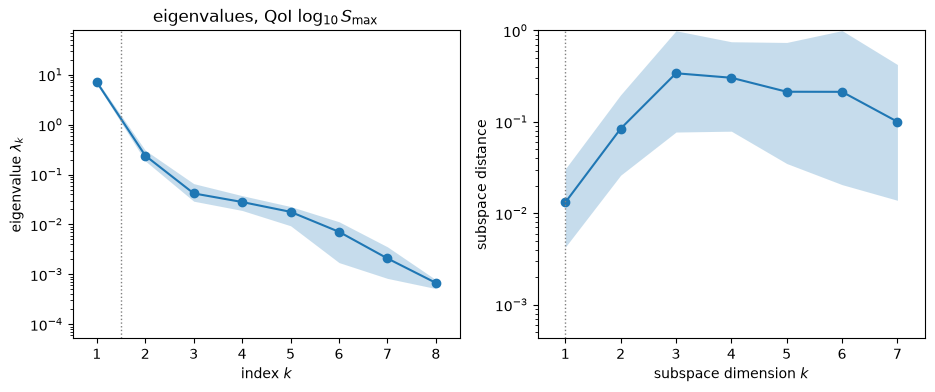

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, ax=axes[0])
axes[0].set_title(r'eigenvalues, QoI $\log_{10}S_{\max}$')
ac.plotting.plot_subspace_errors(sub, ax=axes[1])
plt.close(fig)
lb = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
for i in range(4):
    print(f'lambda{i + 1} = {lam[i]:.4f}, 95 % bootstrap band [{lb[0, i]:.4f}, {lb[1, i]:.4f}]')
print('bootstrap mean subspace distance, k = 1..7:',
      np.array2string(sub.bootstrap_distances.mean(axis=0)[:7], precision=3))
fig

The bootstrap bands are narrow and do not overlap: $\lambda_1 \in [6.51, 7.69]$ and $\lambda_2 \in [0.187, 0.307]$. The one-dimensional subspace is well determined (mean bootstrap distance 0.013 for $k = 1$, against 0.084 for $k = 2$ and 0.34 for $k = 3$). **Choice of dimension: $n = 1$**, from the eigenvalue gap, the small subspace error and the leave-one-out $R^2$ below.

**Eigenvectors.** The first two eigenvectors (normalized inputs):

w1: log10_N -0.378, log10_mu_g -0.819, sigma_g -0.109, kappa -0.079, log10_V +0.397, T -0.095, P +0.041, alpha_c -0.005
w2: log10_N -0.439, log10_mu_g +0.491, sigma_g +0.336, kappa +0.031, log10_V +0.660, T -0.117, P +0.052, alpha_c -0.009
w3: log10_N -0.414, log10_mu_g -0.158, sigma_g +0.695, kappa +0.001, log10_V -0.454, T +0.330, P +0.031, alpha_c +0.062


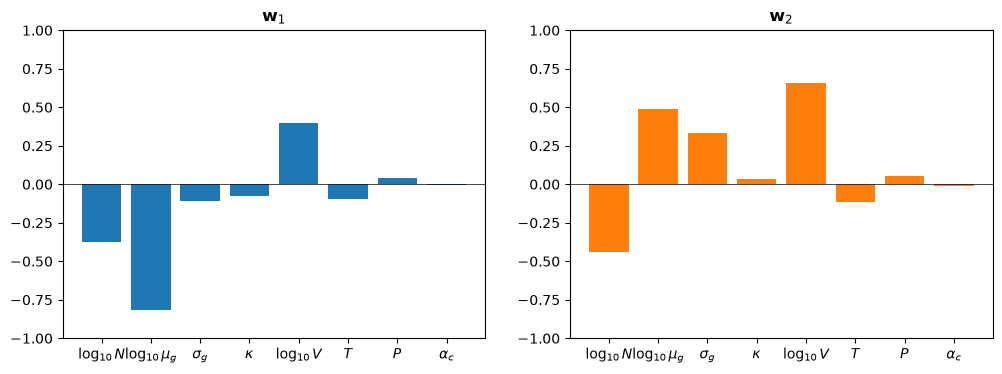

In [10]:
W = sub.W
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in range(2):
    axes[j].bar(range(8), W[:, j], color=f'C{j}')
    axes[j].set_xticks(range(8)); axes[j].set_xticklabels(labels)
    axes[j].axhline(0, color='k', lw=.5); axes[j].set_ylim(-1, 1)
    axes[j].set_title(rf'$\mathbf{{w}}_{j + 1}$')
plt.close(fig)
for j in range(3):
    print(f'w{j + 1}:', ', '.join(f'{n} {W[i, j]:+.3f}' for i, n in enumerate(pd.NAMES)))
fig

$\mathbf w_1$ is a contrast between the updraft and the aerosol: $\log_{10}\mu_g$ has $-0.819$, $\log_{10}V$ $+0.397$ and $\log_{10}N$ $-0.378$; $\sigma_g$ ($-0.109$), $T$ ($-0.095$) and $\kappa$ ($-0.079$) are small, and $P$ ($+0.041$) and $\alpha_c$ ($-0.005$) barely enter. $S_{\max}$ rises with updraft speed (more cooling) and falls with more and larger particles (a larger condensation sink). $\log_{10}N$ and $\log_{10}V$ both span three decades, so their components compare directly: they are nearly equal and opposite ($-0.378$ and $+0.397$), so along $\mathbf w_1$ $S_{\max}$ depends on $N$ and $V$ mostly through $V/N$. $\mathbf w_2$ ($\log_{10}V$ $+0.660$, $\log_{10}\mu_g$ $+0.491$, $\log_{10}N$ $-0.439$, $\sigma_g$ $+0.336$) carries the much smaller second eigenvalue.

**Sufficient summary plots.** Left: $\log_{10}S_{\max}$ against $y_1$, with rows whose supersaturation still rises at 400 m marked, and a cubic in $y_1$. Right: the two active variables, coloured by $\log_{10}S_{\max}$. Polynomial surrogates are fit with `ac.fit_surrogate`, and we print their leave-one-out $R^2$.

LOO R^2 in y1: degree 1 0.9329, degree 2 0.9779, degree 3 0.9808
LOO R^2 in (y1, y2): degree 2 0.9835, degree 3 0.9882
cubic in (y1, y2): residual sd 0.157 (sd of log10 S_max 1.545); rows still rising at 400 m: mean residual -0.039, interior peak +0.015


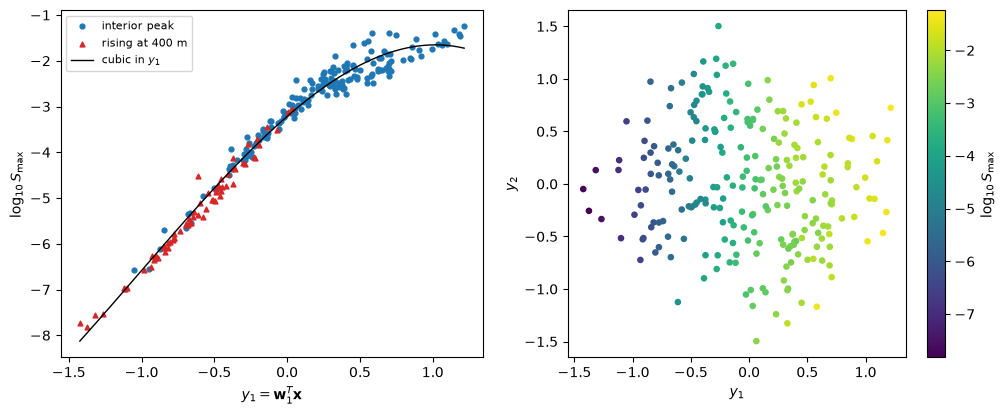

In [11]:
y = Zs @ W[:, :2]
s1 = {d: ac.fit_surrogate(X=Xa, f=fa, subspace=sub, kind='poly', degree=d) for d in (1, 2, 3)}
s2 = {d: ac.fit_surrogate(X=Xa, f=fa, subspace=sub2, kind='poly', degree=d) for d in (2, 3)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y[pka, 0], fa[pka], s=12, c='C0', label='interior peak')
axes[0].scatter(y[~pka, 0], fa[~pka], s=12, c='C3', marker='^', label='rising at 400 m')
yy = np.linspace(y[:, 0].min(), y[:, 0].max(), 200)
axes[0].plot(yy, s1[3].evaluate(yy[:, None]), 'k-', lw=1, label='cubic in $y_1$')
axes[0].set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{x}$'); axes[0].set_ylabel(r'$\log_{10}S_{\max}$')
axes[0].legend(fontsize=8)
sc = axes[1].scatter(y[:, 0], y[:, 1], c=fa, s=14, cmap='viridis')
fig.colorbar(sc, ax=axes[1], label=r'$\log_{10}S_{\max}$')
axes[1].set_xlabel('$y_1$'); axes[1].set_ylabel('$y_2$')
plt.close(fig)
print('LOO R^2 in y1: ' + ', '.join(f'degree {d} {s1[d].loo_r_squared:.4f}' for d in (1, 2, 3)))
print('LOO R^2 in (y1, y2): ' + ', '.join(f'degree {d} {s2[d].loo_r_squared:.4f}' for d in (2, 3)))
r3 = fa - s2[3].evaluate(y)
print(f'cubic in (y1, y2): residual sd {r3.std():.3f} (sd of log10 S_max {fa.std():.3f}); '
      f'rows still rising at 400 m: mean residual {r3[~pka].mean():+.3f}, interior peak {r3[pka].mean():+.3f}')
fig

$\log_{10}S_{\max}$ rises along $y_1$ over about six decades, almost linearly for $y_1 < 0$ and flattening towards the largest $y_1$ (strong updrafts, few small particles): in $y_1$ alone the leave-one-out $R^2$ is 0.9329 (linear), 0.9779 (quadratic) and 0.9808 (cubic). Adding $y_2$ raises the cubic to 0.9882. The cubic in $(y_1, y_2)$ leaves a residual standard deviation of 0.157 decades, against 1.545 for $\log_{10}S_{\max}$ itself. The rows still rising at 400 m lie on the same trend as the others, at the low-$S_{\max}$ end (mean residual $-0.039$ against $+0.015$).

**Two checks on the domain.** The subspace from all rows with gradients on the full Table 1 box (not a uniform design there, since the rows with $\mu_g < 3.16$ nm have no gradients), and from the rows with an interior peak only:

In [12]:
# The lower kappa bound: 0 (the paper's box), 0.05 and 0.2, against 0.1 (all with mu_g >= 3.16 nm)
for kmin in (0.0, 0.05, 0.2):
    sp_k, kp = box(kmin)
    s_k = ac.active_subspace(space=sp_k, X=X[kp], f=f[kp], grads=G[kp], estimator='as', n=1, nboot=500, rng=SEED)
    l_k = s_k.eigenvalues
    print(f'kappa >= {kmin:4.2f}: {kp.sum()} rows, lambda1/lambda2 = {l_k[0] / l_k[1]:6.2f}, '
          f'lambda2/lambda3 = {l_k[1] / l_k[2]:5.2f}, bootstrap distance (k = 1) {s_k.bootstrap_distances.mean(0)[0]:.3f}, '
          f'|w1 . w1(kappa >= 0.1)| = {abs(s_k.W[:, 0] @ W[:, 0]):.3f}, kappa component of w1 {abs(s_k.W[3, 0]):.3f}')
pk_sub = ac.active_subspace(space=space, X=Xa[pka], f=fa[pka], grads=Ga[pka], estimator='as', n=1)
lp = pk_sub.eigenvalues
print(f'interior-peak rows only ({pka.sum()}): lambda1/lambda2 = {lp[0] / lp[1]:.2f}; '
      f'|w1 . w1(all)| = {abs(pk_sub.W[:, 0] @ W[:, 0]):.3f}')
small = Xa[:, 1] <= 0.0                                      # mu_g <= 1 um
lo_s, up_s = space.lower.copy(), space.upper.copy(); up_s[1] = 0.0
sm_sub = ac.active_subspace(space=ac.Uniform(lo_s, up_s, names=pd.NAMES), X=Xa[small], f=fa[small], grads=Ga[small],
                            estimator='as', n=1)
ls_ = sm_sub.eigenvalues
print(f'mu_g <= 1 um only ({small.sum()} rows, {np.sum(small & ~pka)} still rising at 400 m): lambda1/lambda2 = '
      f'{ls_[0] / ls_[1]:.2f}; |w1 . w1(all)| = {abs(sm_sub.W[:, 0] @ W[:, 0]):.3f}')

kappa >= 0.00: 263 rows, lambda1/lambda2 =   1.61, lambda2/lambda3 = 21.36, bootstrap distance (k = 1) 0.340, |w1 . w1(kappa >= 0.1)| = 0.765, kappa component of w1 0.703


kappa >= 0.05: 252 rows, lambda1/lambda2 =  27.82, lambda2/lambda3 =  3.70, bootstrap distance (k = 1) 0.013, |w1 . w1(kappa >= 0.1)| = 1.000, kappa component of w1 0.095


kappa >= 0.20: 216 rows, lambda1/lambda2 =  29.90, lambda2/lambda3 =  5.57, bootstrap distance (k = 1) 0.013, |w1 . w1(kappa >= 0.1)| = 1.000, kappa component of w1 0.058
interior-peak rows only (173): lambda1/lambda2 = 21.62; |w1 . w1(all)| = 0.999
mu_g <= 1 um only (167 rows, 23 still rising at 400 m): lambda1/lambda2 = 15.55; |w1 . w1(all)| = 0.989


On the paper's full $\kappa$ range the estimate breaks down, as expected from the $1/\kappa$ derivative: $\lambda_1/\lambda_2 = 1.61$, the mean bootstrap distance for $k = 1$ is 0.340, and $\mathbf w_1$ is mostly $\kappa$ (component 0.703; $|\mathbf w_1\cdot\mathbf w_1(\kappa\ge0.1)| = 0.765$). With $\kappa \ge 0.05$ or $\kappa \ge 0.2$ the result does not depend on the bound: $\lambda_1/\lambda_2 = 27.82$ and 29.90, distance 0.013, and $|\mathbf w_1\cdot\mathbf w_1(\kappa\ge0.1)| = 1.000$ to three digits in both. The rows with an interior peak alone (173) give the same direction ($|\cos| = 0.999$, $\lambda_1/\lambda_2 = 21.62$), and so do the rows with $\mu_g \le 1$ µm (167 rows, 23 still rising; $|\cos| = 0.989$, $\lambda_1/\lambda_2 = 15.55$), so neither the 400 m cap nor the coarse-mode tail drives the direction.

### Activated fraction

The paper's second output is the activated fraction from Eq. (10). Its gradient follows from that of $\log_{10}S_{\max}$ by the chain rule. Same estimator and sign rule ($\mathbf w_1$ with a positive $\log_{10}V$ component):

activated fraction: eigenvalue ratios [ 1.54 28.58  4.99  1.48] ; lambda1/trace = 0.594
w1: log10_N -0.652, log10_mu_g +0.216, sigma_g -0.151, kappa +0.031, log10_V +0.701, T -0.092, P +0.070, alpha_c -0.015
w2: log10_N +0.242, log10_mu_g +0.961, sigma_g +0.043, kappa +0.102, log10_V -0.068, T -0.022, P -0.022, alpha_c -0.007
|w1(act_frac) . w1(log10 S_max)| = 0.373; LOO R^2 cubic in y1 0.7623, cubic in (y1, y2) 0.9194


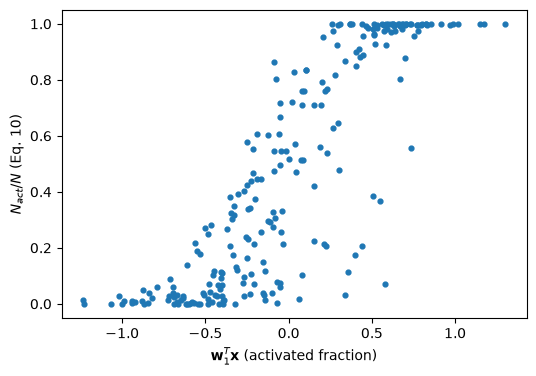

In [13]:
suba = ac.active_subspace(space=space, X=Xa, f=afa, grads=GAa, estimator='as', n=1, nboot=500, rng=SEED)
suba = ac.orient(suba, by='reference', reference=ref[:, :1])
la = suba.eigenvalues
sa = ac.fit_surrogate(X=Xa, f=afa, subspace=suba, kind='poly', degree=3)
print('activated fraction: eigenvalue ratios', np.array2string(la[:4] / la[1:5], precision=2),
      f'; lambda1/trace = {la[0] / la.sum():.3f}')
print('w1:', ', '.join(f'{n} {suba.W[i, 0]:+.3f}' for i, n in enumerate(pd.NAMES)))
suba2 = ac.active_subspace(space=space, X=Xa, f=afa, grads=GAa, estimator='as', n=2)
sa2 = ac.fit_surrogate(X=Xa, f=afa, subspace=suba2, kind='poly', degree=3)
print('w2:', ', '.join(f'{n} {suba2.W[i, 1]:+.3f}' for i, n in enumerate(pd.NAMES)))
print(f'|w1(act_frac) . w1(log10 S_max)| = {abs(suba.W[:, 0] @ W[:, 0]):.3f}; LOO R^2 cubic in y1 {sa.loo_r_squared:.4f}, '
      f'cubic in (y1, y2) {sa2.loo_r_squared:.4f}')
fig, ax = plt.subplots(figsize=(6, 4))
ya = space.to_normalized(Xa) @ suba.W[:, 0]
ax.scatter(ya, afa, s=12)
ax.set_xlabel(r'$\mathbf{w}_1^T\mathbf{x}$ (activated fraction)'); ax.set_ylabel(r'$N_{act}/N$ (Eq. 10)')
plt.close(fig)
fig

For the activated fraction the leading gap comes after $\lambda_2$ ($\lambda_1/\lambda_2 = 1.54$, $\lambda_2/\lambda_3 = 28.58$), so it has a two-dimensional active subspace. $\mathbf w_1$ is again an updraft–number contrast ($\log_{10}V$ $+0.701$, $\log_{10}N$ $-0.652$), and $\mathbf w_2$ is mostly the mode size ($\log_{10}\mu_g$ $+0.961$). Eq. (10) compares $S_{\max}$ with the critical supersaturation of the mode, which depends on $\mu_g$ separately, so $\mathbf w_1$ differs from that of $\log_{10}S_{\max}$ ($|\cos| = 0.373$). A cubic in $y_1$ has leave-one-out $R^2 = 0.7623$; a cubic in $(y_1, y_2)$ has 0.9194. The fraction saturates near 0 or 1 in 99 of the 300 rows (below 0.01 in 51, above 0.99 in 48), which a polynomial cannot follow.

### Comparison with the paper's Sobol' indices

The paper ranks the inputs by Sobol' indices: total indices of $S_{\max}$ from the parcel model and its emulators (Fig. 5, p. 1266; a bar chart) and main indices from the ordinary-least-squares chaos expansions (Table 4, p. 1267). To compare on the same footing we compute main and total Sobol' indices of our cubic surrogate in $(y_1, y_2)$ by pick-freeze sampling ($2^{16}$ base points, seed `SEED`) on the analysis box, and print them beside the paper's order-5 main indices, the diagonal of $\mathbf C$ ($\mathbb E[(\partial f/\partial x_i)^2]$) and the activity scores $\sum_{j\le 2}\lambda_j w_{ij}^2$. The paper lists only the top eight main terms (six single inputs and two interactions); $P$ and $\alpha_c$ are below its eighth term, 0.017. Our box differs from the paper's in $\mu_g$ (from 3.16 nm rather than 1 nm) and in $\kappa$ (from 0.1 rather than 0), so the numbers are not expected to agree exactly. As a check without the surrogate, we also estimate the main indices directly from the stored values: conditional means in 15 equal-count bins of each input over the Latin hypercube, bias-corrected for the within-bin variance, with a 500-replicate bootstrap.

In [14]:
# Main and total Sobol' indices of the cubic surrogate in (y1, y2), by the pick-freeze estimators of
# Saltelli et al. (2010) on 2^16 uniform points of the analysis box (normalized coordinates).
def sobol(g, m, N, rng):
    A, B = rng.uniform(-1, 1, (N, m)), rng.uniform(-1, 1, (N, m))
    fA, fB = g(A), g(B)
    V = np.var(np.concatenate([fA, fB]))
    S, T = np.zeros(m), np.zeros(m)
    for i in range(m):
        ABi = A.copy(); ABi[:, i] = B[:, i]
        fABi = g(ABi)
        S[i] = np.mean(fB * (fABi - fA)) / V
        T[i] = 0.5 * np.mean((fA - fABi) ** 2) / V
    return S, T
g2 = lambda Zn: s2[3].evaluate(Zn @ W[:, :2])
S_main, S_tot = sobol(g2, 8, 2**16, np.random.default_rng(SEED))
nu = Gn.T @ Gn / len(Gn)                                    # C in normalized coordinates
act1 = lam[0] * W[:, 0]**2                                  # activity scores, n = 1
paper_main = {'log10_mu_g': 0.359, 'log10_V': 0.312, 'log10_N': 0.129, 'sigma_g': 0.056, 'T': 0.047,
              'kappa': 0.019}                                # Table 4, OLS order 5, p. 1267
print(f"{'input':11s} {'paper S_i':>9s} {'surr. S_i':>9s} {'surr. T_i':>9s} {'E[(df/dx)^2]':>12s} {'act. score':>10s}")
for i in np.argsort(-S_main):
    n = pd.NAMES[i]
    ps = f"{paper_main[n]:9.3f}" if n in paper_main else f"{'< 0.017':>9s}"
    print(f'{n:11s} {ps} {S_main[i]:9.3f} {S_tot[i]:9.3f} {nu[i, i]:12.4f} {act1[i]:10.4f}')
print(f'sum of main indices: surrogate {S_main.sum():.3f}; paper (top six main terms) {sum(paper_main.values()):.3f}')
print('rank by surrogate main index:', ', '.join(pd.NAMES[i] for i in np.argsort(-S_main)))
print('rank by activity score:      ', ', '.join(pd.NAMES[i] for i in np.argsort(-act1)))
# the same surrogate on the part of the box with mu_g <= 1 um (log10 mu_g in [-2.5, 0])
zc = 2 * (0 - space.lower[1]) / (space.upper[1] - space.lower[1]) - 1
def g_sub(Zn):
    Zn = Zn.copy(); Zn[:, 1] = -1 + (Zn[:, 1] + 1) * (zc + 1) / 2
    return g2(Zn)
S_sub, T_sub = sobol(g_sub, 8, 2**16, np.random.default_rng(SEED))
print('mu_g <= 1 um, surrogate main indices:', ', '.join(f'{pd.NAMES[i]} {S_sub[i]:.3f}' for i in np.argsort(-S_sub)[:5]))
# main indices without a surrogate: 15 equal-count bins of each input, bias-corrected (stored values)
def binned_main(x, y, nb=15):
    groups = np.array_split(np.argsort(x), nb)
    n_g = np.array([len(g) for g in groups])
    mb = np.array([y[g].mean() for g in groups])
    within = np.array([y[g].var(ddof=1) / len(g) for g in groups])
    return (np.sum(n_g * (mb - y.mean())**2) - np.sum(n_g * within)) / len(y) / y.var()
rb = np.random.default_rng(SEED)
for nm, msk in [('full Table 1 box, all 300 rows', np.ones(M, bool)), ('analysis box', keep),
                ('analysis box, interior peak only', keep & peaked)]:
    Sb = np.array([binned_main(X[msk, j], f[msk]) for j in range(8)])
    idx = np.flatnonzero(msk)
    bb = np.array([[binned_main(X[r_, j], f[r_]) for j in (1, 4)] for r_ in (rb.choice(idx, len(idx)) for _ in range(500))])
    ci = np.percentile(bb, [2.5, 97.5], axis=0)
    print(f'binned main indices, {nm} ({msk.sum()} rows): ' + ', '.join(f'{pd.NAMES[j]} {Sb[j]:.2f}' for j in np.argsort(-Sb)[:4])
          + f'; 95 % bootstrap log10_mu_g [{ci[0, 0]:.2f}, {ci[1, 0]:.2f}], log10_V [{ci[0, 1]:.2f}, {ci[1, 1]:.2f}]')

input       paper S_i surr. S_i surr. T_i E[(df/dx)^2] act. score
log10_mu_g      0.359     0.630     0.680       4.8071     4.7472
log10_V         0.312     0.146     0.181       1.2281     1.1133
log10_N         0.129     0.143     0.156       1.0713     1.0104
sigma_g         0.056     0.010     0.015       0.1384     0.0840
kappa           0.019     0.006     0.007       0.0717     0.0440
T               0.047     0.004     0.010       0.0789     0.0633
P             < 0.017     0.002     0.002       0.0136     0.0121
alpha_c       < 0.017     0.000     0.000       0.0028     0.0002
sum of main indices: surrogate 0.941; paper (top six main terms) 0.922
rank by surrogate main index: log10_mu_g, log10_V, log10_N, sigma_g, kappa, T, P, alpha_c
rank by activity score:       log10_mu_g, log10_V, log10_N, sigma_g, T, kappa, P, alpha_c
mu_g <= 1 um, surrogate main indices: log10_mu_g 0.454, log10_V 0.209, log10_N 0.205, sigma_g 0.014, kappa 0.008


binned main indices, full Table 1 box, all 300 rows (300 rows): log10_mu_g 0.72, log10_N 0.09, log10_V 0.07, P 0.02; 95 % bootstrap log10_mu_g [0.69, 0.79], log10_V [0.04, 0.19]


binned main indices, analysis box (240 rows): log10_mu_g 0.67, log10_N 0.16, log10_V 0.08, P 0.01; 95 % bootstrap log10_mu_g [0.63, 0.75], log10_V [0.04, 0.23]


binned main indices, analysis box, interior peak only (173 rows): log10_mu_g 0.66, kappa 0.08, T 0.04, log10_N 0.03; 95 % bootstrap log10_mu_g [0.57, 0.77], log10_V [-0.02, 0.18]


The first four inputs are in the paper's order: $\log_{10}\mu_g$, $\log_{10}V$, $\log_{10}N$, $\sigma_g$; the activity scores of the one-dimensional subspace give the same four. After that the order is not determined: our $\kappa$ (main 0.006, total 0.007) and $T$ (0.004, 0.010) are a tie at the noise level, while the paper has $T$ (0.047) well above $\kappa$ (0.019). The weights differ. The surrogate's main index of $\log_{10}\mu_g$ is 0.630 against the paper's 0.359, and that of $\log_{10}V$ is 0.146 against 0.312, while $\log_{10}N$ agrees (0.143 against 0.129); $\sigma_g$ (0.010 against 0.056) and $T$ (0.004 against 0.047) are 5–10 times smaller than in Table 4. The $\mu_g$ dominance is not an artefact of the surrogate, the $\kappa$ bound or the 400 m cap: the binned estimate from the stored values gives 0.72 for $\log_{10}\mu_g$ on the full Table 1 box (all 300 rows; 95 % bootstrap range 0.69–0.79) and 0.66 on the interior-peak rows of the analysis box alone. It comes from the low-$S_{\max}$ tail at large $\mu_g$: the 82 analysis rows below $10^{-2}$ %, the lower end of the paper's Fig. 1a, which hold most of the variance (above). On the part of the box with $\mu_g \le 1$ µm the surrogate gives 0.454 for $\log_{10}\mu_g$, 0.209 for $\log_{10}V$ and 0.205 for $\log_{10}N$, closer to Table 4. The paper does not say whether its runs for these modes reached $S_{\max} \ge 10^{-2}$ % (`DATA.md`, open questions). The main indices sum to 0.941, and the paper's six single-input terms to 0.922: in both, interactions carry little of the variance.

### Comparison with the paper

| quantity | paper (page) | this notebook |
|---|---|---|
| most important input for $S_{\max}$ | $\log_{10}\mu_g$, main index 0.359 (Table 4, order 5, p. 1267) | $\log_{10}\mu_g$: surrogate main index 0.630; $w_{1}$ component $-0.819$ |
| second | $\log_{10}V$, 0.312 (Table 4) | $\log_{10}V$: 0.146; $+0.397$ |
| third | $\log_{10}N$, 0.129 (Table 4) | $\log_{10}N$: 0.143; $-0.378$ |
| $\log_{10}\mu_g$ main index without a surrogate | — | 0.72 (binned, full Table 1 box, 300 rows); 0.66 (interior-peak analysis rows) |
| $\sigma_g$, $T$, $\kappa$ main indices | 0.056, 0.047, 0.019 (Table 4) | 0.010, 0.004, 0.006 |
| $P$, $\alpha_c$ | below the eighth term, 0.017 (Table 4) | 0.002, 0.000 |
| total-index order | updraft and size first, then number; $\alpha_c$ and $\kappa$ weakest (Fig. 5, text p. 1266) | totals: $\log_{10}\mu_g$ 0.680, $\log_{10}V$ 0.181, $\log_{10}N$ 0.156; $\alpha_c$ 0.000, $P$ 0.002, $\kappa$ 0.007 |
| emulator accuracy for $S_{\max}$ | order-5 OLS chaos expansion (8 inputs), $r^2$ = 0.976 on 20 000 validation points (Table 2, p. 1262) | cubic in one active variable, leave-one-out $R^2$ = 0.981 on 240 points (a different measure and box) |
| active subspace | not reported | on the box with $\mu_g \ge 3.16$ nm and $\kappa \ge 0.1$: $n = 1$, $\lambda_1/\lambda_2 = 29.5$, $\lambda_1$ = 95.4 % of the trace; on the full box (rows with gradients) $\lambda_1/\lambda_2 = 1.61$ |
| range of $S_{\max}$ from the parcel model | Fig. 1a axes $10^{-2}$ % to $10^{1}$ % (20 000 validation points, p. 1261) | $1.5\times10^{-6}$ % to 21.6 %; 86 of 300 rows (82 of 240 analysis rows) below $10^{-2}$ %, all with $\mu_g > 0.1$ µm |
| one-at-a-time curves at the nominal point | Fig. 3a–h, parcel model (p. 1265) | reproduced within reading accuracy at the ends of all eight curves, $S_{\max}$ and activated fraction (`DATA.md`, Accuracy) |
| activated fraction | Fig. 1b, emulator vs parcel model (p. 1261); no sensitivity reported | two-dimensional subspace ($\lambda_2/\lambda_3 = 28.6$), LOO $R^2$ 0.919 |

Our box differs from the paper's in two ways: $\mu_g \ge 3.16$ nm, and $\kappa \ge 0.1$ for the subspace. The parcel code also differs (pyrcel 2.0.0 with Kvaerno5, not the 2015 code with VODE), and the 400 m ascent cap is our choice. The first four inputs are ranked as in the paper; the weights of $\mu_g$ and $V$ do not agree, and the difference sits in the low-$S_{\max}$ tail at large $\mu_g$ that the paper's Fig. 1a does not show. Near the nominal point pyrcel reproduces the paper's Fig. 3.

### References

[1] D. Rothenberg and C. Wang, Metamodeling of droplet activation for global climate models, *Journal of the Atmospheric Sciences* 73(3), 1255–1272, 2016. [doi:10.1175/JAS-D-15-0223.1](https://doi.org/10.1175/JAS-D-15-0223.1)

[2] D. Rothenberg, pyrcel: 0-D adiabatic cloud parcel model, version 2.0.0, [github.com/darothen/pyrcel](https://github.com/darothen/pyrcel) (BSD 3-clause).

[3] M. D. Petters and S. M. Kreidenweis, A single parameter representation of hygroscopic growth and cloud condensation nucleus activity, *Atmospheric Chemistry and Physics* 7(8), 1961–1971, 2007. [doi:10.5194/acp-7-1961-2007](https://doi.org/10.5194/acp-7-1961-2007)

[4] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto and S. Tarantola, Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index, *Computer Physics Communications* 181(2), 259–270, 2010. [doi:10.1016/j.cpc.2009.09.018](https://doi.org/10.1016/j.cpc.2009.09.018)

[5] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

### Acknowledgments

The paper's work was supported by the National Science Foundation Graduate Research Fellowship Program under NSF Grant 1122374, NSF Grant AGS-1339264, the National Research Foundation Singapore through the Singapore–MIT Alliance for Research and Technology and the interdisciplinary research group of the Center for Environmental Sensing and Modeling, and the U.S. Department of Energy, Office of Science (DE-FG02-94ER61937) (p. 1268).

In [15]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 3.4 s
